# Edad cinemática de asociaciones estelares jóvenes con Gaia DR3

**Curso:** Minería de datos para astronomía  
**Fecha:** 15 de noviembre de 2026  
**Autor:** Carlos Eduardo Orozco Garcés

Este cuaderno reproduce el flujo completo, desde la consulta hasta la clasificación. El estudio incluye **TW Hydrae** y **Upper Scorpius**. También incluye **Epsilon Chamaeleontis**. Las tres asociaciones tienen edades publicadas menores de 20 Myr. Lower Centaurus Crux no se utiliza.

La metodología se limita a herramientas vistas en el curso. ADQL se usa para las consultas. `pandas` y `numpy` procesan los datos. `matplotlib` produce las figuras. `astropy` convierte las coordenadas. `GaussianMixture` de `scikit-learn` aplica el modelo no supervisado.

## Metodología

1. SIMBAD identifica los miembros mediante la relación jerárquica `h_link`. La columna `membership` expresa la solidez de cada relación. El número 90 es el umbral mínimo de la consulta; no corresponde a una cantidad de estrellas. Por esta razón, solo se aceptan registros con `membership >= 90`. La tabla `ident` aporta después el identificador de Gaia DR3.
2. El identificador numérico se cruza con `gaiadr3.gaia_source` mediante ADQL. No se cruzan nombres ni posiciones aproximadas.
3. Se eliminan los datos incompletos y los paralajes no positivos. También se descartan las mediciones con error relativo mayor al 20 %. Este límite se aplica al paralaje y a los movimientos propios. La velocidad radial usa el mismo criterio.
4. `SkyCoord` transforma las seis observables a $(X,Y,Z,V_X,V_Y,V_Z)$ en ICRS.
5. Las trayectorias se retroceden linealmente. La edad cinemática corresponde al mínimo de la dispersión espacial tridimensional. Los objetos a más de dos desviaciones estándar del centro en ese instante se consideran contaminantes de campo y se recalcula la edad.
6. La incertidumbre se obtiene con 200 remuestreos con reemplazo. Los percentiles 16 y 84 definen el intervalo.
7. Para buscar candidatos se consulta Gaia alrededor de cada asociación. Los límites corresponden a dos desviaciones estándar en paralaje y movimiento propio. La velocidad radial usa el mismo límite. Un GMM de dos componentes se ajusta en el espacio cartesiano estandarizado. La componente que concentra a los miembros confirmados define la probabilidad de pertenencia.

In [1]:
# En Colab basta ejecutar esta celda una vez.
!pip -q install astroquery astropy scikit-learn


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [2]:
import io
import os
import time
import warnings
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astropy import units as u
from astropy.coordinates import SkyCoord, Distance
from sklearn.mixture import GaussianMixture

warnings.filterwarnings("ignore", message="Unverified HTTPS request")
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.dpi"] = 500
plt.rcParams["savefig.dpi"] = 500
np.random.seed(42)

SIMBAD_TAP = "https://simbad.idia.ac.za/simbad/sim-tap/sync"
GAIA_TAP = "https://129.206.112.47/tap/sync"

GRUPOS = {
    "TW Hydrae": {"simbad": "NAME TW Hya Association", "ra": 165.5, "dec": -34.7, "radio": 10.0},
    "Upper Scorpius": {"simbad": "NAME Upper Sco Association", "ra": 243.0, "dec": -23.4, "radio": 1.0},
    "Epsilon Chamaeleontis": {"simbad": "NAME eps Cha Association", "ra": 180.0, "dec": -78.0, "radio": 2.0},
}

def consulta_tap(endpoint, consulta, intentos=4):
    # Ejecuta ADQL síncrono y devuelve el CSV como DataFrame.
    datos = {"REQUEST": "doQuery", "LANG": "ADQL", "FORMAT": "csv", "QUERY": consulta}
    for intento in range(intentos):
        try:
            respuesta = requests.post(endpoint, data=datos, timeout=90, verify=False)
            respuesta.raise_for_status()
            if respuesta.text.lstrip().startswith("<?xml"):
                raise RuntimeError(respuesta.text[:600])
            return pd.read_csv(io.StringIO(respuesta.text))
        except Exception:
            if intento == intentos - 1:
                raise
            time.sleep(3 * (intento + 1))

print("Servicios y funciones preparados.")

Servicios y funciones preparados.


## Miembros de SIMBAD y cruce con Gaia DR3

La consulta usa `h_link` y `basic` para resolver la relación jerárquica. La tabla `ident` aporta el `source_id` de Gaia DR3.

In [3]:
def miembros_simbad(nombre_grupo, archivo):
    if os.path.exists(archivo):
        return pd.read_csv(archivo, dtype={"source_id": "int64"})
    consulta = f"""
    SELECT DISTINCT c.main_id, c.ra AS ra_simbad, c.dec AS dec_simbad,
           h.membership, i.id AS gaia_id
    FROM h_link AS h
    JOIN basic AS p ON h.parent = p.oid
    JOIN basic AS c ON h.child = c.oid
    JOIN ident AS i ON i.oidref = c.oid
    WHERE p.main_id = '{nombre_grupo}'
      AND h.membership >= 90
      AND i.id LIKE 'Gaia DR3 %'
    """
    tabla = consulta_tap(SIMBAD_TAP, consulta)
    tabla["source_id"] = tabla["gaia_id"].str.replace("Gaia DR3 ", "", regex=False).astype("int64")
    tabla = tabla.drop_duplicates("source_id")
    tabla.to_csv(archivo, index=False)
    return tabla

miembros_catalogo = {}
for numero, (grupo, datos) in enumerate(GRUPOS.items(), 1):
    miembros_catalogo[grupo] = miembros_simbad(datos["simbad"], f"datos/{numero}_simbad.csv")
    print(f"{grupo}: {len(miembros_catalogo[grupo])} identificadores Gaia DR3 únicos")

TW Hydrae: 106 identificadores Gaia DR3 únicos
Upper Scorpius: 5718 identificadores Gaia DR3 únicos
Epsilon Chamaeleontis: 73 identificadores Gaia DR3 únicos


In [4]:
COLUMNAS_GAIA = """source_id,ra,dec,ra_error,dec_error,parallax,parallax_error,
pmra,pmra_error,pmdec,pmdec_error,radial_velocity,radial_velocity_error,
phot_g_mean_mag,bp_rp,ruwe"""

def datos_gaia_por_id(tabla_simbad, archivo, bloque=400):
    # Consulta Gaia por bloques para no producir una sentencia ADQL excesivamente larga.
    if os.path.exists(archivo):
        return pd.read_csv(archivo, dtype={"source_id": "int64"})
    ids = tabla_simbad["source_id"].astype(str).tolist()
    partes = []
    for inicio in range(0, len(ids), bloque):
        lista = ",".join(ids[inicio:inicio + bloque])
        consulta = f"SELECT {COLUMNAS_GAIA} FROM gaiadr3.gaia_source WHERE source_id IN ({lista})"
        partes.append(consulta_tap(GAIA_TAP, consulta))
    gaia = pd.concat(partes, ignore_index=True)
    resultado = tabla_simbad.merge(gaia, on="source_id", how="inner")
    resultado.to_csv(archivo, index=False)
    return resultado

datos_crudos = {}
for numero, grupo in enumerate(GRUPOS, 1):
    print(f"Consulta de Gaia DR3 para {grupo}; puede tardar varios minutos...")
    datos_crudos[grupo] = datos_gaia_por_id(miembros_catalogo[grupo], f"datos/{numero}_gaia.csv")
    print(f"  {len(datos_crudos[grupo])} filas recuperadas")

Consulta de Gaia DR3 para TW Hydrae; puede tardar varios minutos...
  106 filas recuperadas
Consulta de Gaia DR3 para Upper Scorpius; puede tardar varios minutos...
  5718 filas recuperadas
Consulta de Gaia DR3 para Epsilon Chamaeleontis; puede tardar varios minutos...
  73 filas recuperadas


## Limpieza y solución cartesiana completa

El error relativo se calcula como $\sigma_q/|q|$. Se exige un valor menor que 0.20 para el paralaje y ambos movimientos propios. La velocidad radial usa el mismo límite. También se descartan los paralajes negativos o nulos. Dentro de cada asociación se retiran los paralajes situados a más de tres desviaciones estándar de la media inicial.

In [5]:
def limpiar(tabla):
    columnas = ["ra", "dec", "parallax", "parallax_error", "pmra", "pmra_error",
                "pmdec", "pmdec_error", "radial_velocity", "radial_velocity_error"]
    limpia = tabla.dropna(subset=columnas).copy()
    limpia = limpia[limpia["parallax"] > 0]
    for valor, error in [("parallax", "parallax_error"), ("pmra", "pmra_error"),
                         ("pmdec", "pmdec_error"), ("radial_velocity", "radial_velocity_error")]:
        limpia = limpia[(limpia[error] / limpia[valor].abs()) < 0.20]
    media, sigma = limpia["parallax"].mean(), limpia["parallax"].std()
    limpia = limpia[(limpia["parallax"] - media).abs() <= 3 * sigma]
    return limpia.reset_index(drop=True)

def a_cartesianas(tabla):
    c = SkyCoord(
        ra=tabla["ra"].to_numpy() * u.deg,
        dec=tabla["dec"].to_numpy() * u.deg,
        distance=Distance(parallax=tabla["parallax"].to_numpy() * u.mas),
        pm_ra_cosdec=tabla["pmra"].to_numpy() * u.mas/u.yr,
        pm_dec=tabla["pmdec"].to_numpy() * u.mas/u.yr,
        radial_velocity=tabla["radial_velocity"].to_numpy() * u.km/u.s,
        frame="icrs",
    )
    salida = tabla.copy()
    salida[["x", "y", "z"]] = c.cartesian.xyz.to(u.pc).value.T
    salida[["vx", "vy", "vz"]] = c.velocity.d_xyz.to(u.km/u.s).value.T
    return salida

datos_limpios = {}
for grupo, tabla in datos_crudos.items():
    datos_limpios[grupo] = a_cartesianas(limpiar(tabla))
    print(f"{grupo}: {len(tabla)} iniciales -> {len(datos_limpios[grupo])} con solución 6D confiable")

TW Hydrae: 106 iniciales -> 15 con solución 6D confiable
Upper Scorpius: 5718 iniciales -> 530 con solución 6D confiable
Epsilon Chamaeleontis: 73 iniciales -> 21 con solución 6D confiable


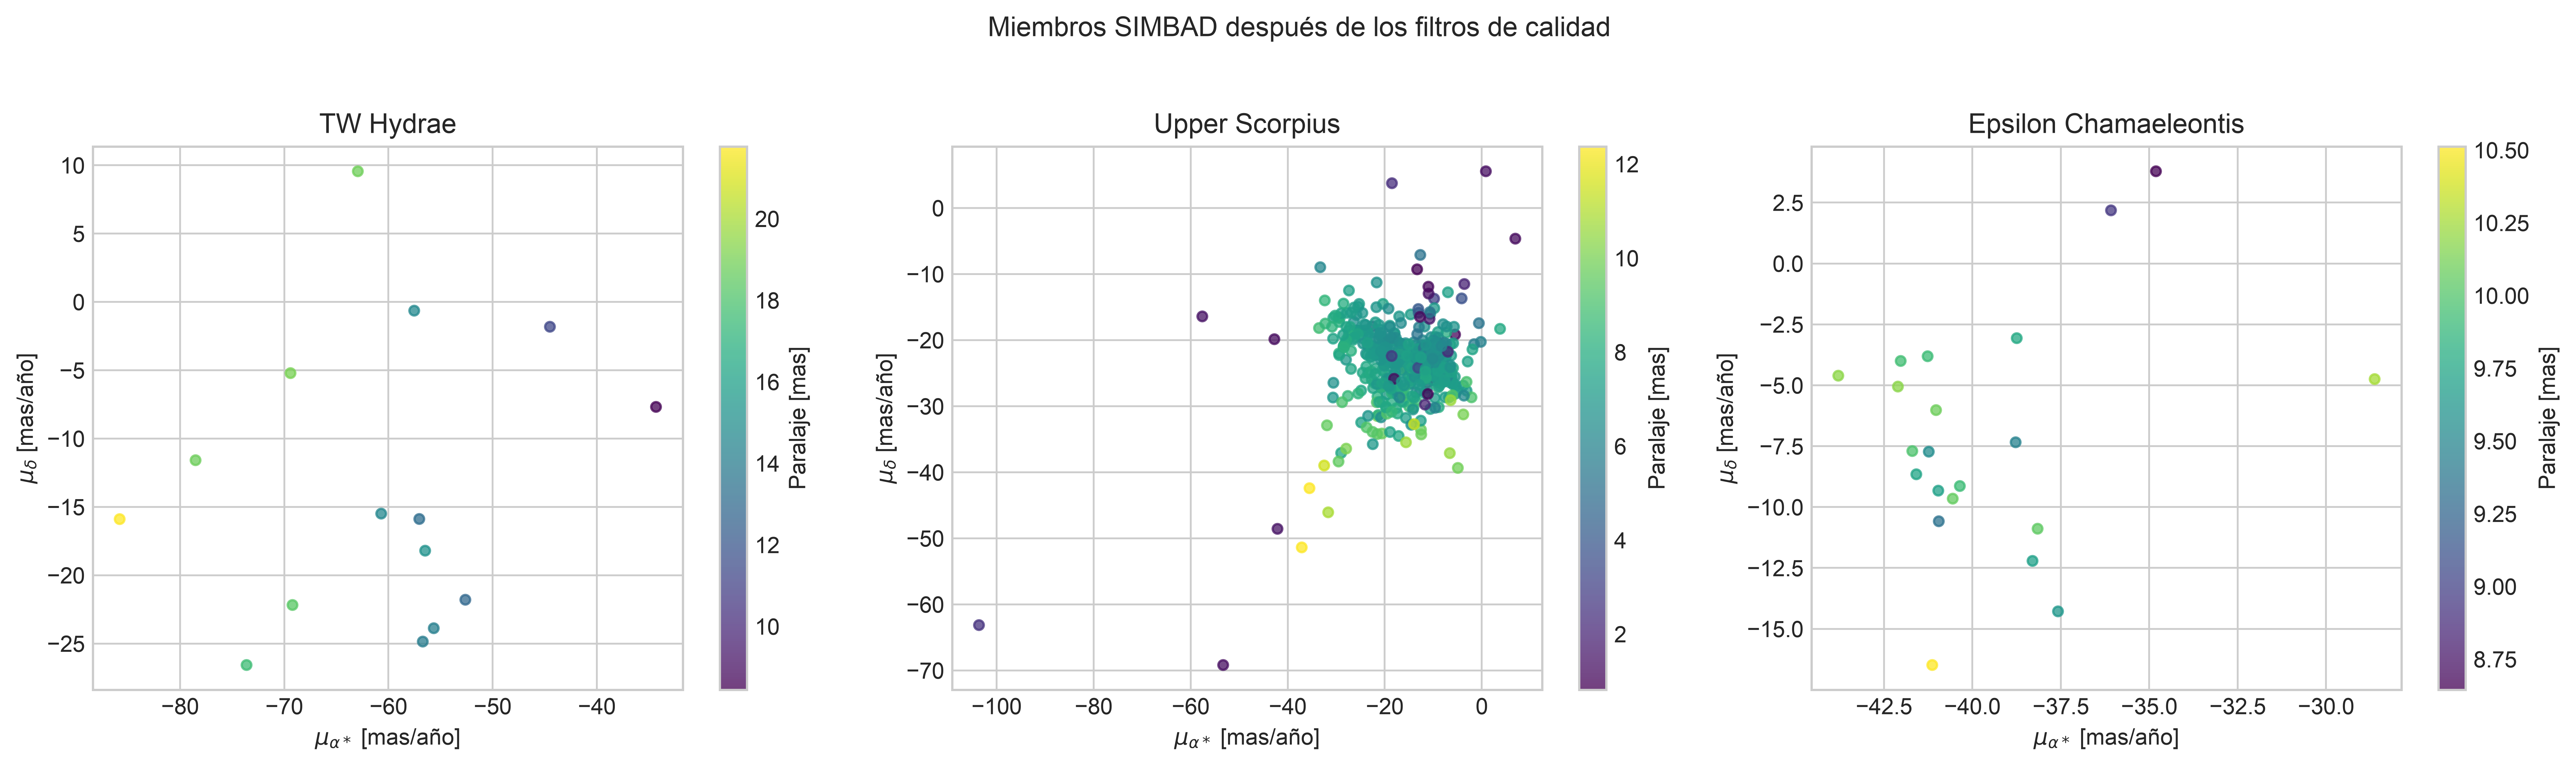

In [6]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.5))
for (grupo, tabla), ax in zip(datos_limpios.items(), ejes):
    puntos = ax.scatter(tabla["pmra"], tabla["pmdec"], c=tabla["parallax"], s=18, alpha=.75, cmap="viridis")
    ax.set(title=grupo, xlabel=r"$\mu_{\alpha*}$ [mas/año]", ylabel=r"$\mu_\delta$ [mas/año]")
    fig.colorbar(puntos, ax=ax, label="Paralaje [mas]")
fig.suptitle("Miembros SIMBAD después de los filtros de calidad", y=1.03)
plt.tight_layout()
plt.show()

**Lectura de la figura.** Cada panel muestra el movimiento propio de los miembros que superaron los filtros. El color representa el paralaje. Una concentración compacta indica que las estrellas comparten un movimiento aparente compatible. Los cambios de color revelan diferencias de distancia dentro del grupo. La extensión de Upper Scorpius es mayor que la de las otras asociaciones, como se espera para una población numerosa que ocupa una región física amplia. Esta figura permite reconocer la coherencia cinemática, pero no basta para confirmar membresía porque el movimiento propio también depende de la distancia.

## Retroceso lineal y edad cinemática

Para un tiempo de mirada al pasado $t>0$:

$$\vec r(t)=\vec r(0)-1.022712\,t\,\vec v,$$

Aquí, $t$ está en Myr. La posición se expresa en pc. La velocidad se expresa en km/s. La dispersión es la raíz de la media de las distancias cuadráticas al centro del grupo. El mínimo marca la máxima convergencia.

TW Hydrae: 1 contaminantes retirados; edad = 3.90 -0.66/+0.85 Myr


Upper Scorpius: 18 contaminantes retirados; edad = 0.00 -0.00/+0.00 Myr


Epsilon Chamaeleontis: 2 contaminantes retirados; edad = 1.70 -0.75/+0.45 Myr


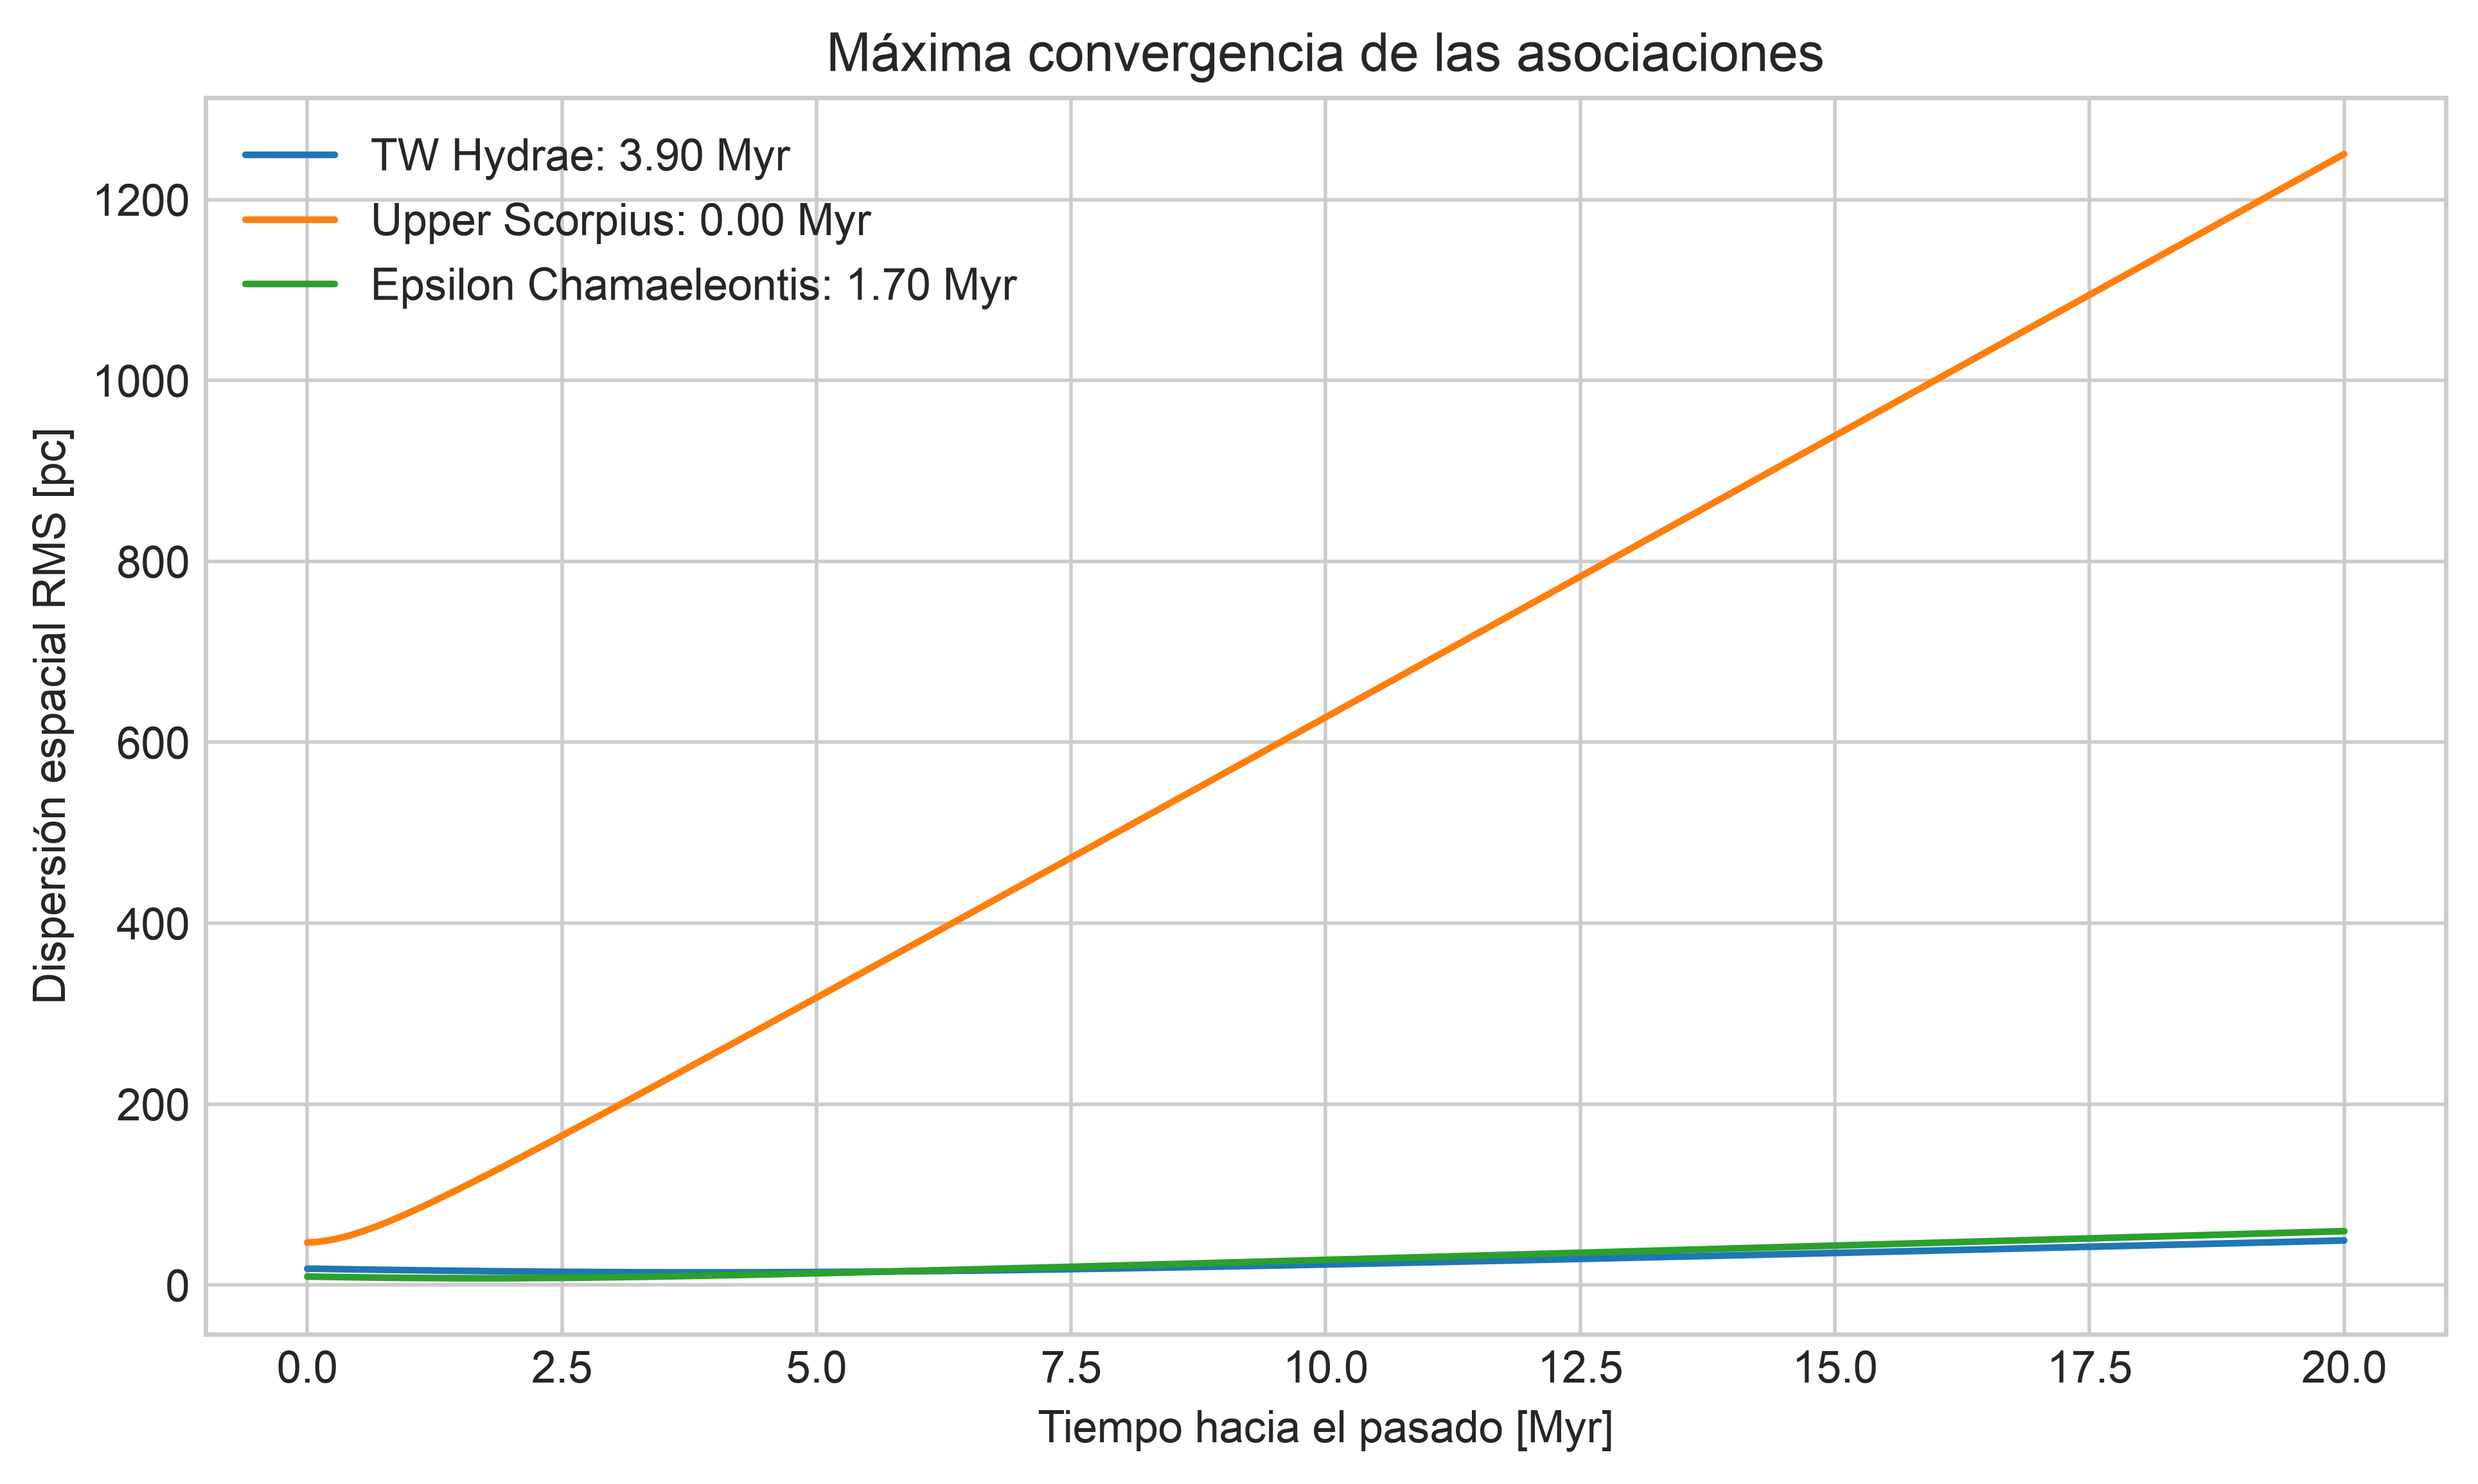

In [7]:
KM_S_A_PC_MYR = 1.022712
TIEMPOS = np.linspace(0, 20, 401)

def curva_convergencia(tabla, tiempos=TIEMPOS):
    r = tabla[["x", "y", "z"]].to_numpy()
    v = tabla[["vx", "vy", "vz"]].to_numpy()
    dispersion = []
    for t in tiempos:
        pasado = r - KM_S_A_PC_MYR * t * v
        centro = pasado.mean(axis=0)
        dispersion.append(np.sqrt(np.mean(np.sum((pasado - centro) ** 2, axis=1))))
    return np.asarray(dispersion)

def quitar_contaminantes(tabla):
    curva = curva_convergencia(tabla)
    edad_inicial = TIEMPOS[np.argmin(curva)]
    r = tabla[["x", "y", "z"]].to_numpy()
    v = tabla[["vx", "vy", "vz"]].to_numpy()
    pasado = r - KM_S_A_PC_MYR * edad_inicial * v
    distancias = np.linalg.norm(pasado - pasado.mean(axis=0), axis=1)
    limite = distancias.mean() + 2 * distancias.std()
    mascara = distancias <= limite
    return tabla.loc[mascara].reset_index(drop=True), edad_inicial, limite

def edad_y_error(tabla, repeticiones=200):
    curva = curva_convergencia(tabla)
    edad = TIEMPOS[np.argmin(curva)]
    rng = np.random.default_rng(42)
    edades = []
    for _ in range(repeticiones):
        muestra = tabla.iloc[rng.integers(0, len(tabla), len(tabla))]
        edades.append(TIEMPOS[np.argmin(curva_convergencia(muestra))])
    p16, p84 = np.percentile(edades, [16, 84])
    return edad, edad - p16, p84 - edad, curva, np.asarray(edades)

resultados_edad = {}
fig, ax = plt.subplots(figsize=(9, 5))
for grupo, tabla in datos_limpios.items():
    depurada, edad_inicial, limite = quitar_contaminantes(tabla)
    edad, err_menos, err_mas, curva, edades = edad_y_error(depurada)
    resultados_edad[grupo] = {"tabla": depurada, "edad": edad, "menos": err_menos,
                              "mas": err_mas, "curva": curva, "bootstrap": edades}
    ax.plot(TIEMPOS, curva, label=f"{grupo}: {edad:.2f} Myr")
    print(f"{grupo}: {len(tabla) - len(depurada)} contaminantes retirados; "
          f"edad = {edad:.2f} -{err_menos:.2f}/+{err_mas:.2f} Myr")
ax.set(xlabel="Tiempo hacia el pasado [Myr]", ylabel="Dispersión espacial RMS [pc]",
       title="Máxima convergencia de las asociaciones")
ax.legend()
plt.show()

**Lectura de la figura.** El eje horizontal retrocede desde el presente. El eje vertical mide el tamaño RMS del grupo. Un mínimo interno señala el instante en que las trayectorias reconstruidas ocupan el menor volumen. TW Hydrae alcanza ese punto cerca de 3.90 Myr. Epsilon Chamaeleontis lo alcanza cerca de 1.70 Myr. Estas edades cinemáticas sugieren una configuración pasada más compacta, pero no equivalen por sí solas a la edad de formación estelar. La curva de Upper Scorpius tiene su mínimo en 0 Myr. Por tanto, la muestra se dispersa al retroceder bajo este modelo y no ofrece una edad cinemática resuelta.

## Búsqueda de candidatos con GMM

La consulta de candidatos usa Gaia DR3. Se define un cono alrededor de cada grupo. Las ventanas de $\pm2\sigma$ se calculan solo con los miembros SIMBAD limpios. El modelo de mezcla contiene dos gaussianas: una representa la concentración del grupo y otra el campo. Las seis variables cartesianas se estandarizan para que posiciones y velocidades tengan escalas comparables. La componente cuya probabilidad media es mayor entre los miembros confirmados se identifica como el grupo.

In [8]:
def candidatos_gaia(grupo, confirmados, archivo):
    if os.path.exists(archivo):
        resultado = pd.read_csv(archivo, dtype={"source_id": "int64"})
    else:
        info = GRUPOS[grupo]
        limites = {}
        for col in ["parallax", "pmra", "pmdec", "radial_velocity"]:
            media, sigma = confirmados[col].mean(), confirmados[col].std()
            limites[col] = (media - 2*sigma, media + 2*sigma)
        consulta = f"""
        SELECT TOP 100 {COLUMNAS_GAIA}
        FROM gaiadr3.gaia_source
        WHERE 1=CONTAINS(POINT('ICRS',ra,dec),
                         CIRCLE('ICRS',{info['ra']},{info['dec']},{info['radio']}))
          AND parallax BETWEEN {limites['parallax'][0]} AND {limites['parallax'][1]}
          AND pmra BETWEEN {limites['pmra'][0]} AND {limites['pmra'][1]}
          AND pmdec BETWEEN {limites['pmdec'][0]} AND {limites['pmdec'][1]}
          AND radial_velocity BETWEEN {limites['radial_velocity'][0]} AND {limites['radial_velocity'][1]}
          AND radial_velocity IS NOT NULL
        """
        resultado = consulta_tap(GAIA_TAP, consulta)
    resultado = resultado.dropna(subset=["parallax", "pmra", "pmdec", "radial_velocity"]).copy()
    centro = SkyCoord(GRUPOS[grupo]["ra"] * u.deg, GRUPOS[grupo]["dec"] * u.deg)
    posiciones = SkyCoord(resultado["ra"].to_numpy() * u.deg, resultado["dec"].to_numpy() * u.deg)
    resultado = resultado[posiciones.separation(centro).deg <= GRUPOS[grupo]["radio"]]
    for valor, error in [("parallax", "parallax_error"), ("pmra", "pmra_error"),
                         ("pmdec", "pmdec_error"), ("radial_velocity", "radial_velocity_error")]:
        resultado = resultado[(resultado[error] / resultado[valor].abs()) < 0.20]
    resultado = resultado.head(100)
    resultado.to_csv(archivo, index=False)
    return resultado

def ajustar_gmm(confirmados, candidatos):
    ids_confirmados = set(confirmados["source_id"].astype("int64"))
    todos = pd.concat([confirmados, a_cartesianas(candidatos)], ignore_index=True)
    todos = todos.drop_duplicates("source_id").reset_index(drop=True)
    variables = ["x", "y", "z", "vx", "vy", "vz"]
    X = todos[variables]
    Xz = (X - X.mean()) / X.std()
    modelo = GaussianMixture(n_components=2, covariance_type="full", random_state=42)
    modelo.fit(Xz)
    probabilidades = modelo.predict_proba(Xz)
    conocidos = todos["source_id"].astype("int64").isin(ids_confirmados).to_numpy()
    componente_grupo = np.argmax(probabilidades[conocidos].mean(axis=0))
    todos["probabilidad_miembro"] = probabilidades[:, componente_grupo]
    todos["confirmado_simbad"] = conocidos
    nuevos = todos[(~todos["confirmado_simbad"]) & (todos["probabilidad_miembro"] >= 0.80)]
    return todos, nuevos.sort_values("probabilidad_miembro", ascending=False), modelo

resultados_gmm = {}
for numero, (grupo, resultado) in enumerate(resultados_edad.items(), 1):
    print(f"Consulta de candidatos para {grupo}...")
    candidatos = candidatos_gaia(grupo, resultado["tabla"], f"datos/{numero}_candidatos.csv")
    todos, nuevos, modelo = ajustar_gmm(resultado["tabla"], candidatos)
    resultados_gmm[grupo] = {"todos": todos, "nuevos": nuevos, "modelo": modelo}
    print(f"  {len(candidatos)} fuentes consultadas; {len(nuevos)} candidatos nuevos con P >= 0.80")

Consulta de candidatos para TW Hydrae...
  7 fuentes consultadas; 3 candidatos nuevos con P >= 0.80
Consulta de candidatos para Upper Scorpius...


  24 fuentes consultadas; 1 candidatos nuevos con P >= 0.80
Consulta de candidatos para Epsilon Chamaeleontis...
  11 fuentes consultadas; 0 candidatos nuevos con P >= 0.80


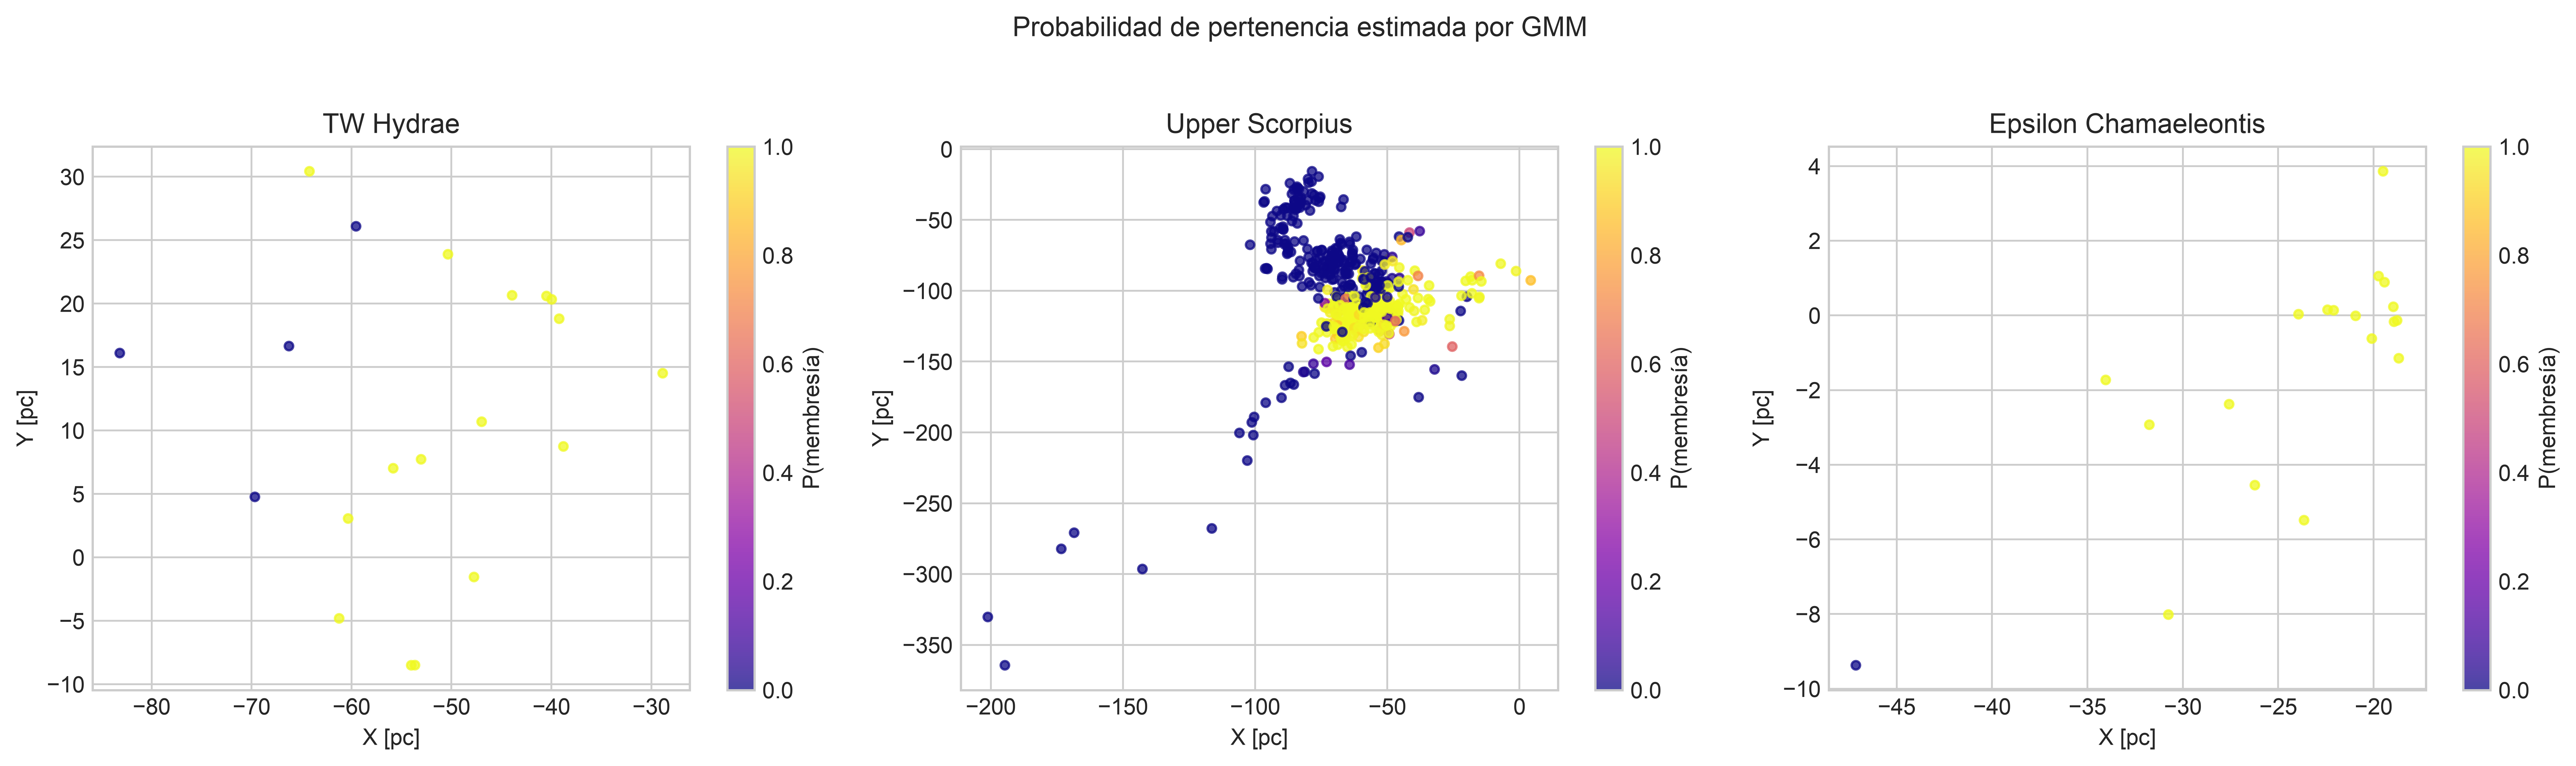


 TW Hydrae


,source_id,ra,dec,parallax,pmra,pmdec,radial_velocity,probabilidad_miembro
14,5446990503905219840,154.642936,-33.819503,11.693040,-41.073413,-4.343126,8.504177,1.0
15,5446669442213589760,154.382128,-34.633261,18.916825,-46.252162,-20.891482,8.577747,1.0
17,5398210052063095808,172.833172,-36.397376,14.305607,-54.365153,-15.903471,18.073013,1.0



 Upper Scorpius


,source_id,ra,dec,parallax,pmra,pmdec,radial_velocity,probabilidad_miembro
524,6242571416681263360,243.124162,-23.041275,5.894869,-1.55848,-22.626582,-40.029537,0.994368



 Epsilon Chamaeleontis


,source_id,ra,dec,parallax,pmra,pmdec,radial_velocity,probabilidad_miembro


In [9]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.5))
for (grupo, resultado), ax in zip(resultados_gmm.items(), ejes):
    tabla = resultado["todos"]
    puntos = ax.scatter(tabla["x"], tabla["y"], c=tabla["probabilidad_miembro"],
                        cmap="plasma", vmin=0, vmax=1, s=14, alpha=.75)
    ax.set(title=grupo, xlabel="X [pc]", ylabel="Y [pc]")
    fig.colorbar(puntos, ax=ax, label="P(membresía)")
fig.suptitle("Probabilidad de pertenencia estimada por GMM", y=1.03)
plt.tight_layout()
plt.show()

for grupo, resultado in resultados_gmm.items():
    print("\n", grupo)
    display(resultado["nuevos"][["source_id", "ra", "dec", "parallax",
                                  "pmra", "pmdec", "radial_velocity",
                                  "probabilidad_miembro"]].head(10))

**Lectura de la figura.** Los ejes muestran la proyección espacial $X$-$Y$. El color indica la probabilidad asignada por el GMM. Los tonos de probabilidad alta marcan fuentes cercanas al patrón de los miembros confirmados dentro del espacio de seis dimensiones usado por el modelo. La proyección puede superponer objetos que difieren en $Z$ o en velocidad. Por eso, un punto de color intenso no demuestra pertenencia física. El resultado selecciona objetivos para una verificación posterior.

## Resultados consolidados

- **TW Hydrae:** 106 miembros Gaia. La muestra contiene 15 soluciones 6D. Se retiró 1 contaminante. La edad es $3.90_{-0.66}^{+0.85}$ Myr. La búsqueda consultó 7 fuentes y encontró 3 candidatos.
- **Upper Scorpius:** 5718 miembros Gaia. La muestra contiene 530 soluciones 6D. Se retiraron 18 contaminantes. El mínimo aparece en 0.00 Myr como límite del modelo. La búsqueda consultó 24 fuentes y encontró 1 candidato.
- **Epsilon Chamaeleontis:** 73 miembros Gaia. La muestra contiene 21 soluciones 6D. Se retiraron 2 contaminantes. La edad es $1.70_{-0.75}^{+0.45}$ Myr. La búsqueda consultó 11 fuentes y no encontró candidatos.

TW Hydrae presenta tres candidatos con $P \geq 0.80$:

- `5446990503905219840`
- `5446669442213589760`
- `5398210052063095808`

Upper Scorpius presenta el candidato `6242571416681263360`. No se encontraron candidatos para Epsilon Chamaeleontis.

## Discusión

- **Calidad de los datos.** La solución 6D exige velocidad radial, por lo cual la muestra útil es menor que el catálogo de miembros. El corte relativo de 20 % privilegia medidas compatibles con la inversión de paralaje y con una extrapolación lineal estable. El filtro de tres desviaciones estándar elimina paralajes incompatibles sin imponer una distancia externa.
- **Interpretación física de la edad.** Una asociación joven conserva parte de la memoria de su estado inicial en las posiciones y velocidades de sus estrellas. El retroceso busca el momento de mayor compactación. El mínimo de TW Hydrae a 3.90 Myr y el de Epsilon Chamaeleontis a 1.70 Myr son compatibles con una expansión posterior. No prueban que todas las estrellas nacieran en un único punto. La formación estelar puede prolongarse en el tiempo.
- **Upper Scorpius.** El mínimo en 0 Myr significa que el grupo no se vuelve más compacto al retroceder con velocidad constante. Este resultado puede reflejar subestructuras cinemáticas. También puede surgir por la gran extensión de la asociación o por una historia dinámica que el modelo lineal no representa. El valor no debe interpretarse como una edad física nula.
- **Límites dinámicos.** El método no incluye el potencial galáctico. Tampoco representa las interacciones internas ni las binarias no resueltas. Estos efectos alteran las velocidades y degradan la reconstrucción al aumentar el tiempo de retroceso.
- **Contaminación.** Retirar fuentes alejadas del centro pasado reduce la influencia de estrellas de campo o medidas perturbadas. El límite de dos desviaciones estándar queda explícito en el código. La misma regla se aplica a cada asociación.
- **Significado físico de los candidatos.** El GMM busca fuentes que comparten el patrón espacial y cinemático de los miembros conocidos. Una probabilidad alta apoya una posible historia dinámica común. No demuestra un origen compartido. El umbral de 0.80 produce una lista conservadora para una verificación posterior. La confirmación requiere espectroscopía. La edad estelar también debe resultar compatible con la asociación.
- **Incertidumbre.** El intervalo percentil del remuestreo mide sensibilidad a la composición de la muestra. No incorpora de forma completa covarianzas astrométricas ni errores sistemáticos de Gaia, por lo que es una incertidumbre estadística interna.

## Conclusiones

1. El cruce por `source_id` conecta de forma inequívoca la membresía jerárquica de SIMBAD con la astrometría Gaia DR3.
2. Los filtros de completitud y error relativo permiten construir una solución cartesiana ICRS de seis dimensiones para cada asociación.
3. TW Hydrae alcanza su mínimo de dispersión en $3.90_{-0.66}^{+0.85}$ Myr. Epsilon Chamaeleontis alcanza el mínimo en $1.70_{-0.75}^{+0.45}$ Myr. Ambos mínimos apoyan una configuración pasada más compacta seguida por expansión. No constituyen por sí solos una fecha exacta de formación estelar.
4. Upper Scorpius presenta el mínimo en 0.00 Myr. La ausencia de convergencia pasada dentro del modelo lineal puede indicar subestructura o una evolución dinámica más compleja. El resultado no representa una edad física nula.
5. El GMM identifica tres candidatos para TW Hydrae. Upper Scorpius presenta uno. Epsilon Chamaeleontis no presenta candidatos con $P \geq 0.80$. Estas fuentes comparten el patrón del grupo según el modelo, pero aún no son miembros confirmados.
6. Los resultados son una primera aproximación. Un estudio físico definitivo debe incorporar la dinámica galáctica. También debe considerar las covarianzas de Gaia. Los candidatos requieren confirmación espectroscópica.

## Referencias y reproducibilidad

- Curso *Minería de datos para astronomía*, Clase 12: Aprendizaje de Máquina No Supervisado.
- SIMBAD Astronomical Database, CDS.
- Gaia Collaboration, Gaia Data Release 3.

El cuaderno contiene las consultas y los umbrales. También registra la semilla aleatoria y cada transformación. La ejecución secuencial regenera las tablas y las figuras.